# Лабораторная работа 1

**Полносвязные нейронные сети и обратное распространение ошибки**

Тема: предсказание отменят ли бронь номера в отеле

In [3]:
import pandas as pd

pd.options.display.max_columns = None
df = pd.read_csv("data/hotel_bookings.csv")

## 1-2. Анализ и предобрабтка данных

In [4]:
df.head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,0.0,0,FB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,303.0,NaN,0,Transient,103.0,0,1,Check-Out,2015-07-03
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,82.0,0,1,Canceled,2015-05-06
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,0,0,D,D,0,No Deposit,15.0,NaN,0,Transient,105.5,0,0,Canceled,2015-04-22


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

**Перевод**

hotel — отель;

is_canceled — отменён (бронирование);

lead_time — время до заезда (количество дней между датой бронирования и датой заезда);

arrival_date_year — год заезда;

arrival_date_month — месяц заезда;

arrival_date_week_number — номер недели заезда;

arrival_date_day_of_month — день месяца заезда;

stays_in_weekend_nights — количество ночей, проведённых в выходные;

stays_in_week_nights — количество ночей, проведённых в будние дни;

adults — количество взрослых;

children — количество детей;

babies — количество младенцев;

meal — тип питания;

country — страна (происхождения гостя);

market_segment — сегмент рынка (категория клиентов);

distribution_channel — канал распределения (способ бронирования: онлайн‑турагент, офлайн‑турагент и т. д.);

is_repeated_guest — повторный гость (признак того, что гость уже останавливался в отеле);

previous_cancellations — количество предыдущих отмен бронирований;

previous_bookings_not_canceled — количество предыдущих не отменённых бронирований;

reserved_room_type — зарезервированный тип номера;

assigned_room_type — присвоенный (фактический) тип номера;

booking_changes — количество изменений в бронировании;

deposit_type — тип депозита (гарантии бронирования);

agent — агент (идентификатор турагента или агентства);

company — компания (идентификатор компании, оплачивающей проживание);

days_in_waiting_list — количество дней в листе ожидания;

customer_type — тип клиента;

adr — средняя дневная ставка (Average Daily Rate, цена за ночь);

required_car_parking_spaces — количество требуемых мест на парковке;

total_of_special_requests — общее количество специальных запросов;

reservation_status — статус бронирования;

reservation_status_date — дата статуса бронирования.

In [6]:
print(df['is_canceled'].value_counts())

print(df['is_canceled'].value_counts(normalize=True) * 100)



is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64


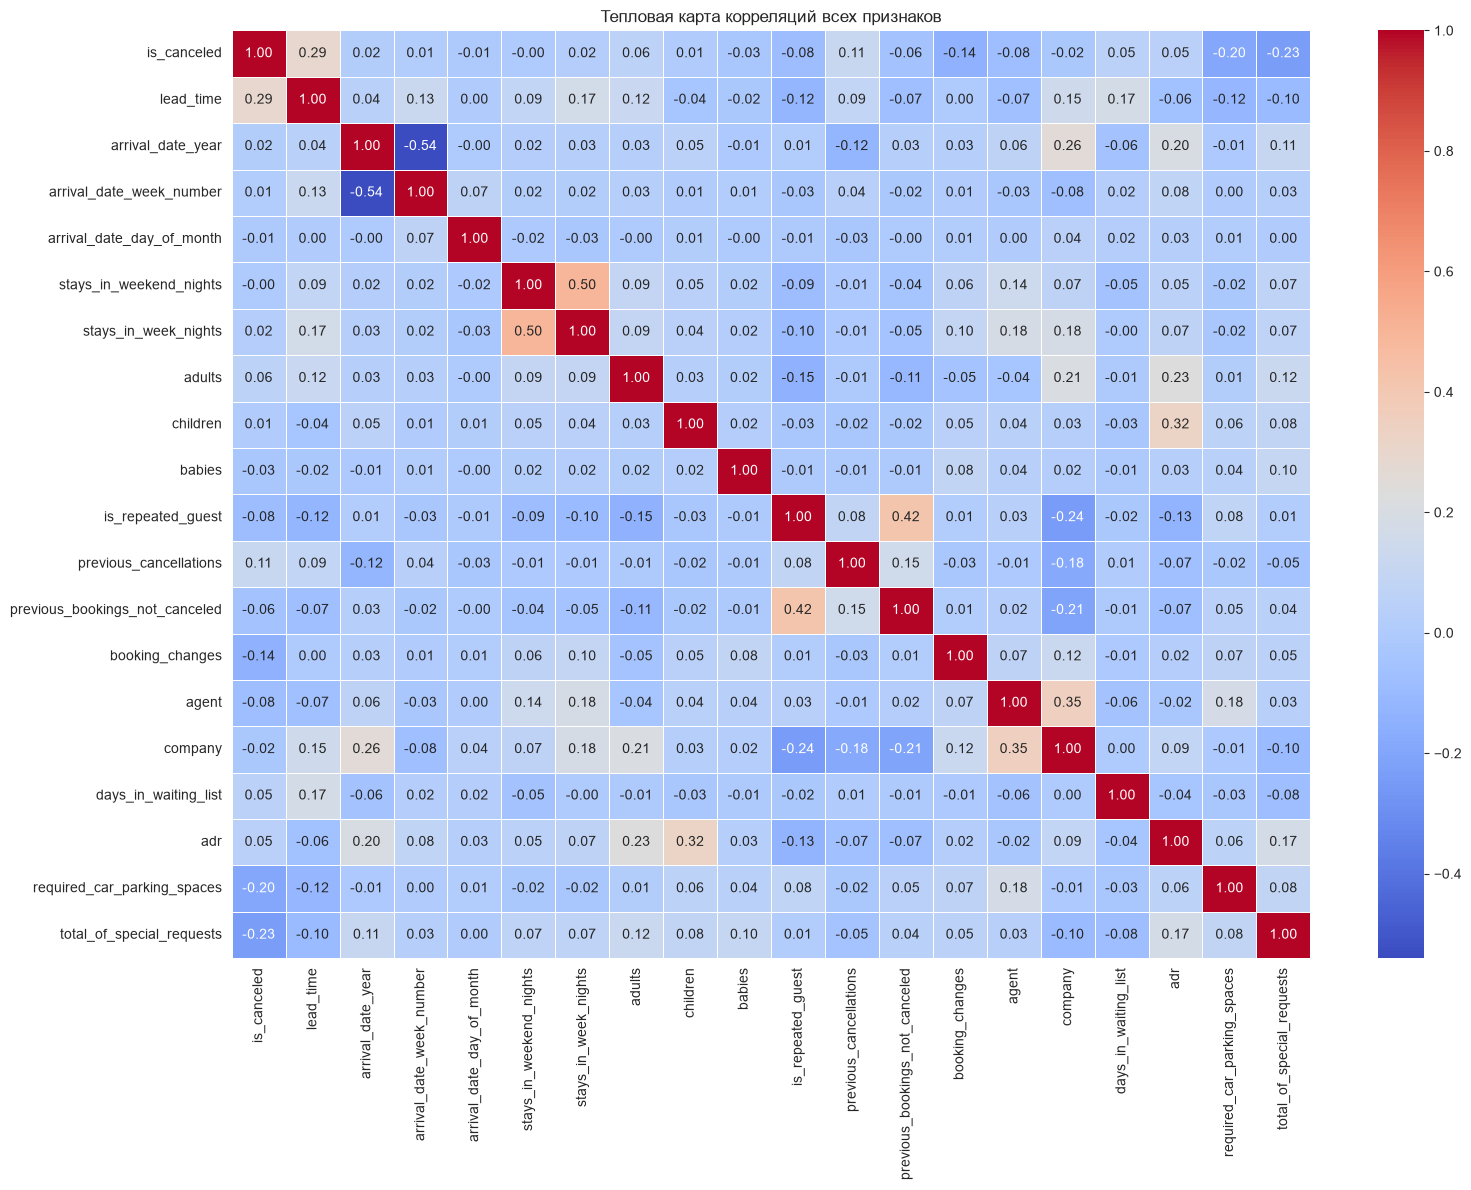

In [7]:
# КОРРЕЛЯЦИОННАЯ МАТРИЦА И ТЕПЛОВАЯ КАРТА
import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df.select_dtypes(include=['int32', 'int64', 'float64']).copy()

plt.figure(figsize=(16, 12))
corr_matrix = numeric_df.corr()  # можно добавить method='spearman'

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Тепловая карта корреляций всех признаков')
plt.tight_layout()
plt.show()

In [8]:
pd.set_option('display.max_columns', 32)
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


Смотрим NULL значения

In [9]:
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 32)

null = pd.DataFrame({
    'Null Values': df.isna().sum(),
    'Percentage Null Values': (df.isna().sum() / df.shape[0]) * 100
})
print(null)

                                Null Values  Percentage Null Values
hotel                                     0                0.000000
is_canceled                               0                0.000000
lead_time                                 0                0.000000
arrival_date_year                         0                0.000000
arrival_date_month                        0                0.000000
arrival_date_week_number                  0                0.000000
arrival_date_day_of_month                 0                0.000000
stays_in_weekend_nights                   0                0.000000
stays_in_week_nights                      0                0.000000
adults                                    0                0.000000
children                                  4                0.003350
babies                                    0                0.000000
meal                                      0                0.000000
country                                 488     

Заполняем пропуски

In [10]:
null_with_values = null[null['Null Values'] > 0]
print(null_with_values)

# Заполнить пропуски в 'country' наиболее частой страной
most_common_country = df['country'].mode()[0]
df['country'] = df['country'].fillna(most_common_country)

# Для 'agent': заполнить 0
df['agent'] = df['agent'].fillna(0)

# Для 'company': создать бинарный флаг
df['is_company_booking'] = df['company'].notna().astype(int)
# Удалить исходный столбец, он больше не нужен
df.drop('company', axis=1, inplace=True)


          Null Values  Percentage Null Values
children            4                0.003350
country           488                0.408744
agent           16340               13.686238
company        112593               94.306893


Проверка на нал значения

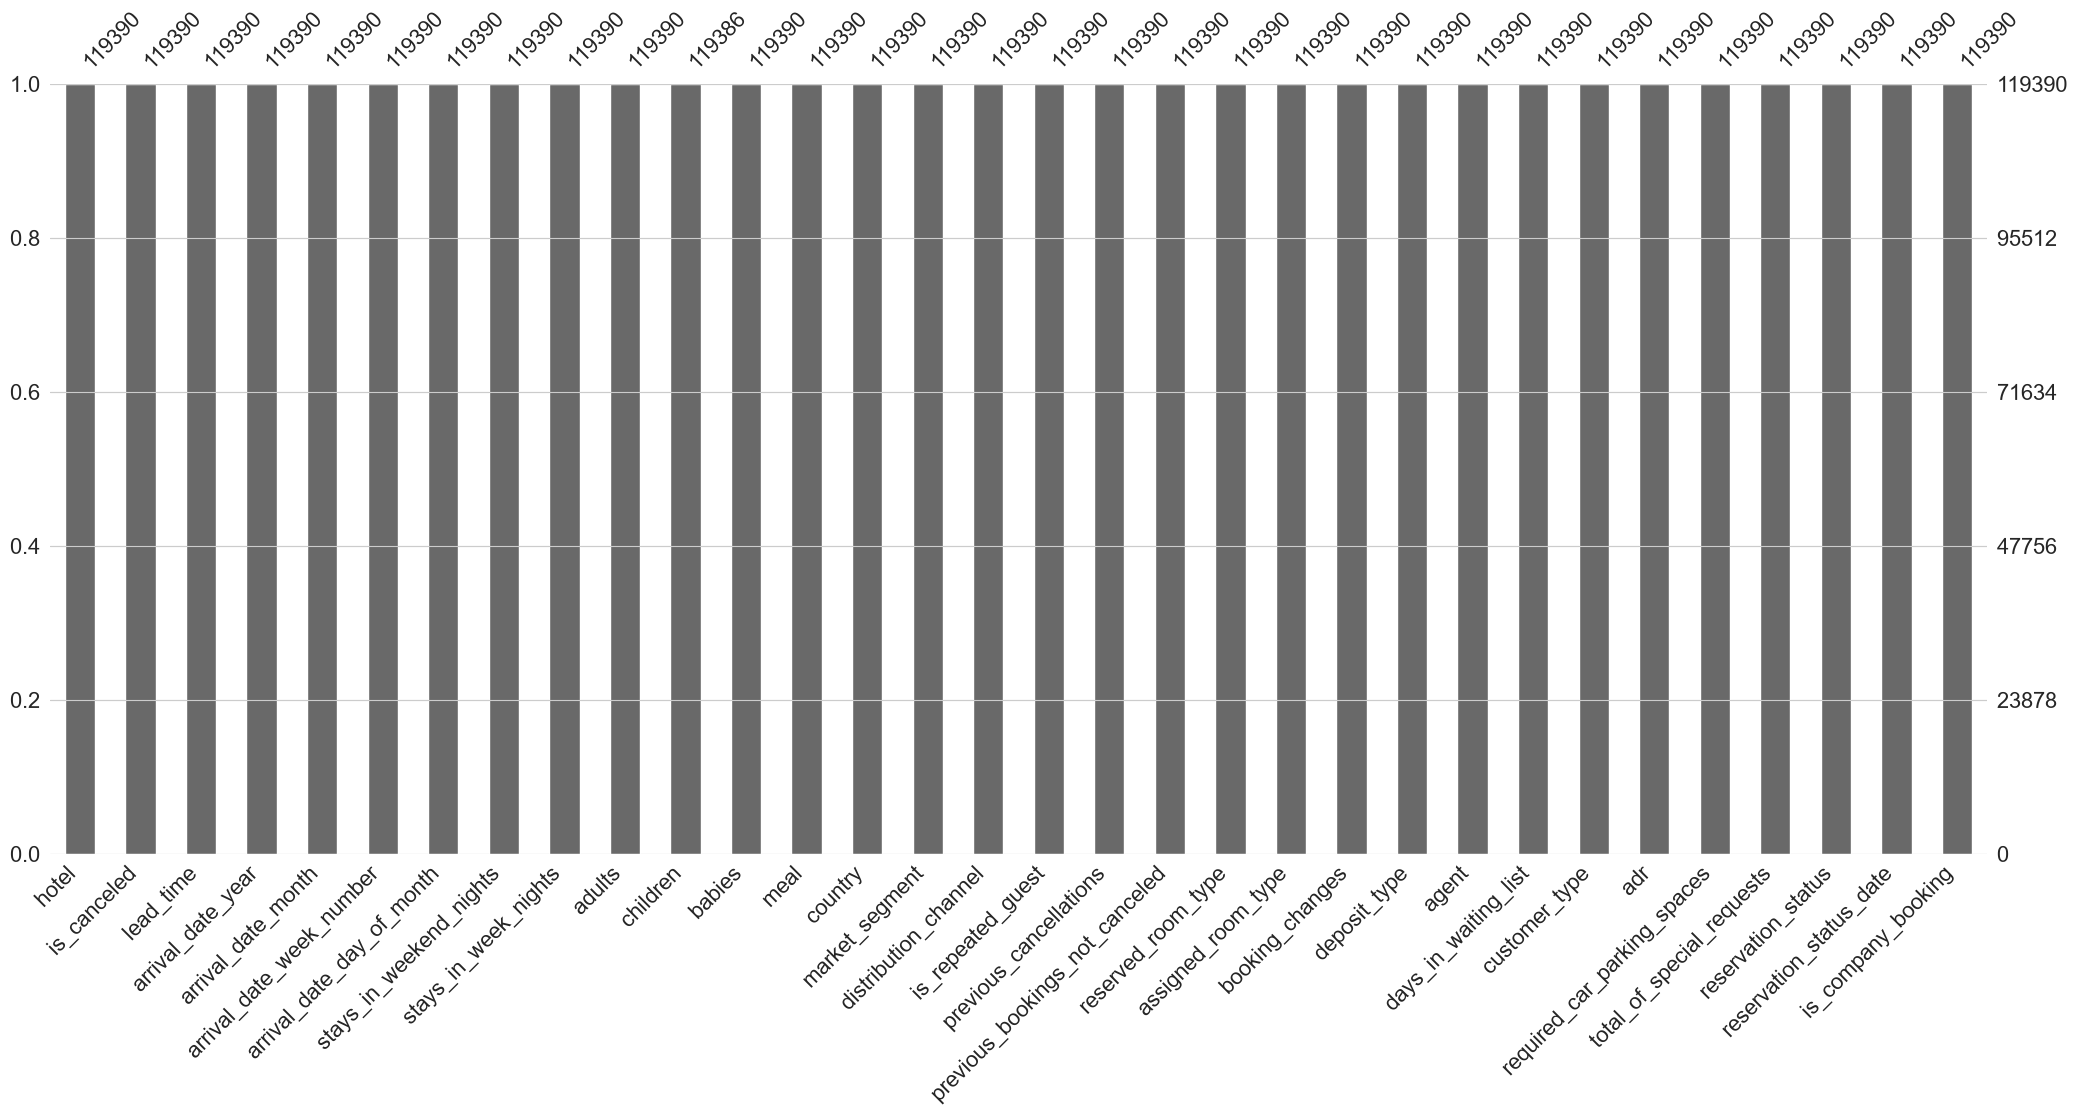

In [11]:
import missingno as msno

msno.bar(df)
plt.show()

Смотрим пустые заявки без клиентов

In [12]:
filter = (df.children == 0) & (df.adults == 0) & (df.babies == 0)
df[filter]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,is_company_booking
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,0.0,0,SC,PRT,Corporate,Corporate,0,0,0,A,I,1,No Deposit,0.0,0,Transient-Party,0.00,0,0,Check-Out,2015-10-06,1
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,0.0,0,SC,PRT,Corporate,Corporate,0,0,0,A,I,0,No Deposit,0.0,0,Transient,0.00,0,0,Check-Out,2015-10-12,1
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,0.0,0,SC,ESP,Groups,TA/TO,0,0,0,A,C,0,No Deposit,38.0,0,Transient-Party,0.00,0,0,Check-Out,2015-11-23,0
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,0.0,0,SC,PRT,Groups,TA/TO,0,0,0,A,A,1,No Deposit,308.0,122,Transient-Party,0.00,0,0,Check-Out,2016-01-04,0
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,0.0,0,SC,PRT,Groups,TA/TO,0,0,0,A,C,1,No Deposit,308.0,122,Transient-Party,0.00,0,0,Check-Out,2016-01-05,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115029,City Hotel,0,107,2017,June,26,27,0,3,0,0.0,0,BB,CHE,Online TA,TA/TO,0,0,0,A,A,1,No Deposit,7.0,0,Transient,100.80,0,0,Check-Out,2017-06-30,0
115091,City Hotel,0,1,2017,June,26,30,0,1,0,0.0,0,SC,PRT,Complementary,Direct,0,0,0,E,K,0,No Deposit,0.0,0,Transient,0.00,1,1,Check-Out,2017-07-01,0
116251,City Hotel,0,44,2017,July,28,15,1,1,0,0.0,0,SC,SWE,Online TA,TA/TO,0,0,0,A,K,2,No Deposit,425.0,0,Transient,73.80,0,0,Check-Out,2017-07-17,0
116534,City Hotel,0,2,2017,July,28,15,2,5,0,0.0,0,SC,RUS,Online TA,TA/TO,0,0,0,A,K,1,No Deposit,9.0,0,Transient-Party,22.86,0,1,Check-Out,2017-07-22,0


Удаляем их

In [13]:
df = df[~filter]
df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,is_company_booking
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,0.0,0,Transient,0.00,0,0,Check-Out,2015-07-01,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,0.0,0,Transient,0.00,0,0,Check-Out,2015-07-01,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,0.0,0,Transient,75.00,0,0,Check-Out,2015-07-02,0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,0,Transient,75.00,0,0,Check-Out,2015-07-02,0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0,Transient,98.00,0,1,Check-Out,2015-07-03,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,0,Transient,96.14,0,0,Check-Out,2017-09-06,0
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,0,Transient,225.43,0,2,Check-Out,2017-09-07,0
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,0,Transient,157.71,0,4,Check-Out,2017-09-07,0
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.0,0,Transient,104.40,0,0,Check-Out,2017-09-07,0


Меняем тип детей

In [14]:
df['children'] = df['children'].fillna(0).astype(int)

print(df['children'].isna().sum())
print(df['children'].unique())

0
[ 0  1  2 10  3]


Смотрим откуда больше всего гостей

In [15]:
country_wise_guests = df[df['is_canceled'] == 0]['country'].value_counts().reset_index()
country_wise_guests.columns = ['country', 'No of guests']
country_wise_guests

,country,No of guests
0,PRT,21398
1,GBR,9668
2,FRA,8468
3,ESP,6383
4,DEU,6067
...,...,...
160,SDN,1
161,ATF,1
162,TJK,1
163,SLE,1


Смотрим среднею ценность номера

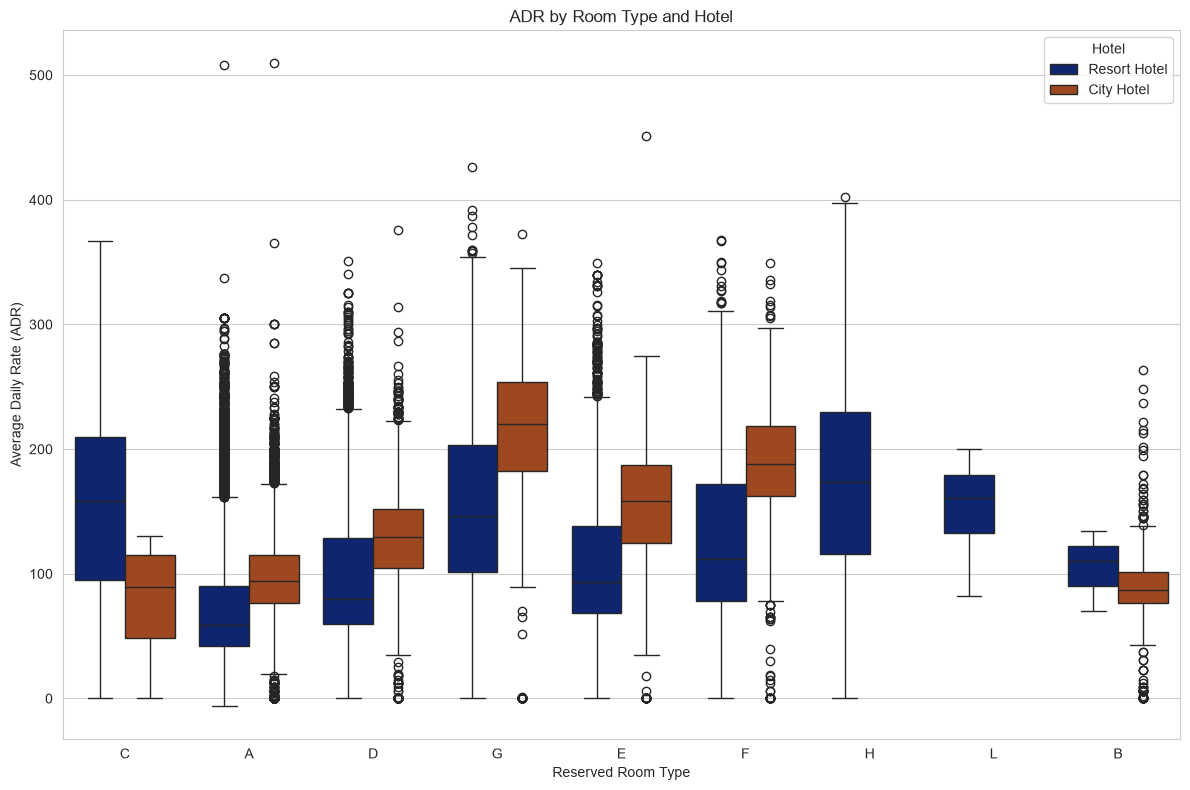

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

data = df[df['is_canceled'] == 0]

plt.figure(figsize=(12, 8))
sns.boxplot(
    data=data,
    x='reserved_room_type',
    y='adr',
    hue='hotel',
    palette='dark'
)
plt.title('ADR by Room Type and Hotel')
plt.xlabel('Reserved Room Type')
plt.ylabel('Average Daily Rate (ADR)')
plt.legend(title='Hotel')
plt.tight_layout()
plt.show()


Как меняется цена за ночь в течение года?

In [17]:
data_resort = df[(df['hotel'] == 'Resort Hotel') & (df['is_canceled'] == 0)]
data_city = df[(df['hotel'] == 'City Hotel') & (df['is_canceled'] == 0)]

In [18]:
# 1 отель
resort_hotel = data_resort.groupby(['arrival_date_month'])['adr'].mean().reset_index()
resort_hotel

,arrival_date_month,adr
0,April,75.867816
1,August,181.205892
2,December,68.410104
3,February,54.147478
4,January,48.761125
5,July,150.122528
6,June,107.974850
7,March,57.056838
8,May,76.657558
9,November,48.706289


In [19]:
# 2 отель

city_hotel = data_city.groupby(['arrival_date_month'])['adr'].mean().reset_index()
city_hotel

,arrival_date_month,adr
0,April,111.962267
1,August,118.674598
2,December,88.401855
3,February,86.520062
4,January,82.330983
5,July,115.818019
6,June,117.874360
7,March,90.658533
8,May,120.669827
9,November,86.946592


In [20]:
final_hotel = resort_hotel.merge(city_hotel, on='arrival_date_month')
final_hotel.columns = ['month', 'price_for_resort', 'price_for_city_hotel']
final_hotel

,month,price_for_resort,price_for_city_hotel
0,April,75.867816,111.962267
1,August,181.205892,118.674598
2,December,68.410104,88.401855
3,February,54.147478,86.520062
4,January,48.761125,82.330983
5,July,150.122528,115.818019
6,June,107.974850,117.874360
7,March,57.056838,90.658533
8,May,76.657558,120.669827
9,November,48.706289,86.946592


In [21]:
import pandas as pd


def sort_month(df, column_name):
    # Определяем порядок месяцев
    months_order = [
        'January', 'February', 'March', 'April', 'May', 'June',
        'July', 'August', 'September', 'October', 'November', 'December'
    ]

    df[column_name] = pd.Categorical(
        df[column_name],
        categories=months_order,
        ordered=True
    )

    return df.sort_values(column_name).reset_index(drop=True)


sorted_df = sort_month(df, 'arrival_date_month')


In [22]:
final_prices = sort_month(final_hotel, 'month')
final_prices

,month,price_for_resort,price_for_city_hotel
0,January,48.761125,82.330983
1,February,54.147478,86.520062
2,March,57.056838,90.658533
3,April,75.867816,111.962267
4,May,76.657558,120.669827
5,June,107.974850,117.874360
6,July,150.122528,115.818019
7,August,181.205892,118.674598
8,September,96.416860,112.776582
9,October,61.775449,102.004672


А сколько гостей в месяц?

In [23]:
# 1 отель
resort_guests = data_resort['arrival_date_month'].value_counts().reset_index()
resort_guests.columns = ['month', 'no of guests']
resort_guests

,month,no of guests
0,August,3257
1,July,3137
2,October,2575
3,March,2571
4,April,2550
5,May,2535
6,February,2308
7,September,2102
8,June,2037
9,December,2014


In [24]:
# 2 отель

city_guests = data_city['arrival_date_month'].value_counts().reset_index()
city_guests.columns = ['month', 'no of guests']
city_guests

,month,no of guests
0,August,5367
1,July,4770
2,May,4568
3,June,4358
4,October,4326
5,September,4283
6,March,4049
7,April,4010
8,February,3051
9,November,2676


In [25]:
final_guests = resort_guests.merge(city_guests, on='month')
final_guests.columns = ['month', 'no of guests in resort', 'no of guest in city hotel']
final_guests

,month,no of guests in resort,no of guest in city hotel
0,August,3257,5367
1,July,3137,4770
2,October,2575,4326
3,March,2571,4049
4,April,2550,4010
5,May,2535,4568
6,February,2308,3051
7,September,2102,4283
8,June,2037,4358
9,December,2014,2377


In [26]:
final_guests = sort_month(final_guests, 'month')
final_guests

,month,no of guests in resort,no of guest in city hotel
0,January,1866,2249
1,February,2308,3051
2,March,2571,4049
3,April,2550,4010
4,May,2535,4568
5,June,2037,4358
6,July,3137,4770
7,August,3257,5367
8,September,2102,4283
9,October,2575,4326


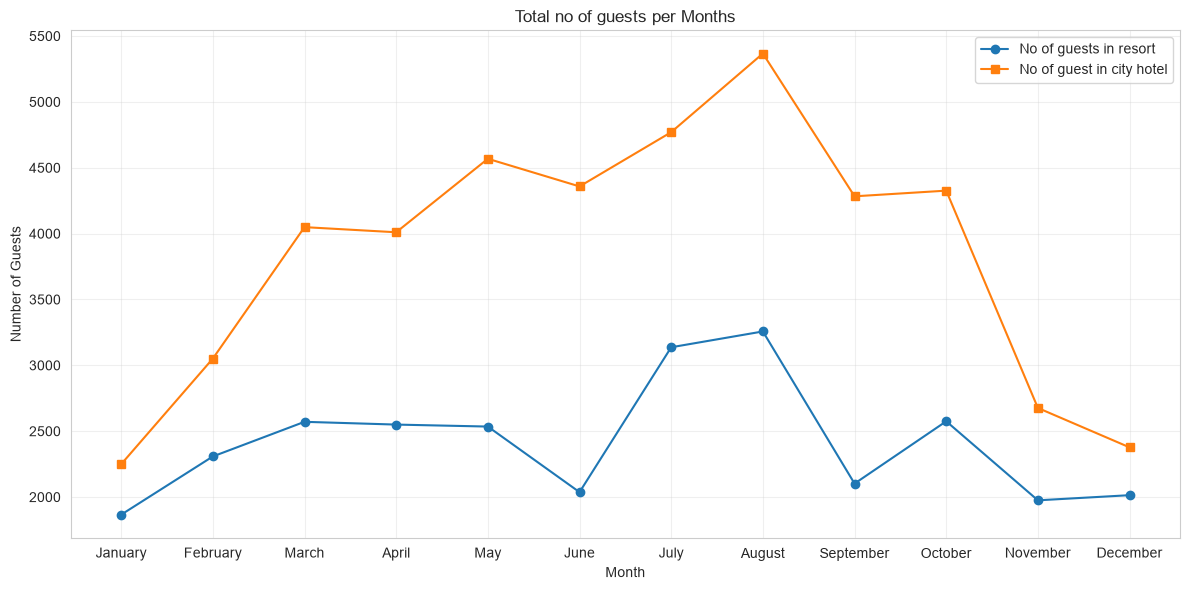

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(final_guests['month'], final_guests['no of guests in resort'],
         label='No of guests in resort', marker='o')
plt.plot(final_guests['month'], final_guests['no of guest in city hotel'],
         label='No of guest in city hotel', marker='s')

plt.title('Total no of guests per Months')
plt.xlabel('Month')
plt.ylabel('Number of Guests')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Как долго люди остаются в отеле?

In [28]:
filter = df['is_canceled'] == 0
data = df[filter]
data.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,is_company_booking
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,0,Transient,98.0,0,1,Check-Out,2015-07-03,0


In [29]:
data['total_nights'] = data['stays_in_weekend_nights'] + data['stays_in_week_nights']
data.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,is_company_booking,total_nights
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,...,0,0,C,C,3,No Deposit,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,...,0,0,C,C,4,No Deposit,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,...,0,0,A,C,0,No Deposit,0.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,0,1
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0,0,BB,GBR,Corporate,Corporate,...,0,0,A,A,0,No Deposit,304.0,0,Transient,75.0,0,0,Check-Out,2015-07-02,0,1
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0,0,BB,GBR,Online TA,TA/TO,...,0,0,A,A,0,No Deposit,240.0,0,Transient,98.0,0,1,Check-Out,2015-07-03,0,2


In [30]:
stay = data.groupby(['total_nights', 'hotel']).agg('count').reset_index()
stay = stay.iloc[:, :3]
stay = stay.rename(columns={'is_canceled': 'Number of stays'})
stay

,total_nights,hotel,Number of stays
0,0,City Hotel,251
1,0,Resort Hotel,371
2,1,City Hotel,9155
3,1,Resort Hotel,6579
4,2,City Hotel,10983
...,...,...,...
57,46,Resort Hotel,1
58,48,City Hotel,1
59,56,Resort Hotel,1
60,60,Resort Hotel,1


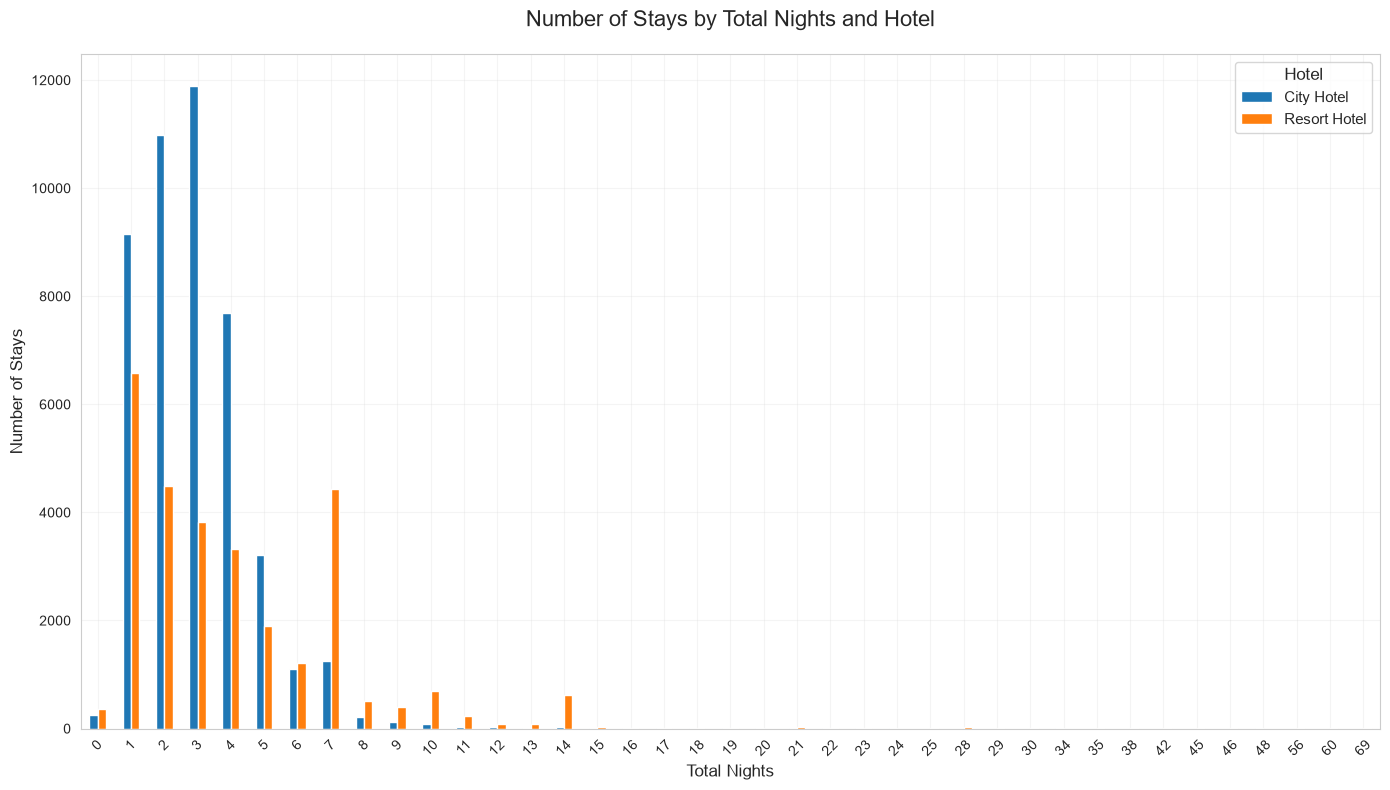

In [31]:
import matplotlib.pyplot as plt

grouped = stay.groupby(['total_nights', 'hotel'])['Number of stays'].sum().unstack()

ax = grouped.plot(
    kind='bar',
    figsize=(14, 8),
    color=['#1f77b4', '#ff7f0e']
)

ax.set_title('Number of Stays by Total Nights and Hotel', fontsize=16, pad=20)
ax.set_xlabel('Total Nights', fontsize=12)
ax.set_ylabel('Number of Stays', fontsize=12)
ax.legend(title='Hotel', fontsize=11, title_fontsize=12)
ax.grid(True, alpha=0.2)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Смотрим корреляцию с целевым признаком

In [32]:
correlation = numeric_df.corr()['is_canceled'].abs().sort_values(ascending=False)
correlation

is_canceled                       1.000000
lead_time                         0.293123
total_of_special_requests         0.234658
required_car_parking_spaces       0.195498
booking_changes                   0.144381
previous_cancellations            0.110133
is_repeated_guest                 0.084793
agent                             0.083114
adults                            0.060017
previous_bookings_not_canceled    0.057358
days_in_waiting_list              0.054186
adr                               0.047557
babies                            0.032491
stays_in_week_nights              0.024765
company                           0.020642
arrival_date_year                 0.016660
arrival_date_week_number          0.008148
arrival_date_day_of_month         0.006130
children                          0.005048
stays_in_weekend_nights           0.001791
Name: is_canceled, dtype: float64

Удаляем бесполезные столбцы

In [33]:
useless_col = ['days_in_waiting_list', 'arrival_date_year', 'arrival_date_year', 'assigned_room_type',
               'booking_changes',
               'reservation_status', 'country', 'days_in_waiting_list']

df.drop(useless_col, axis=1, inplace=True)

Смотрим категариальные признаки

In [34]:
cat_cols = [
    col for col in df.columns
    if df[col].dtype in ['O', 'string', 'category']
]
print(cat_cols)

['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'reservation_status_date']


In [35]:
cat_df = df[cat_cols]
cat_df.head()

,hotel,arrival_date_month,meal,market_segment,distribution_channel,reserved_room_type,deposit_type,customer_type,reservation_status_date
0,Resort Hotel,July,BB,Direct,Direct,C,No Deposit,Transient,2015-07-01
1,Resort Hotel,July,BB,Direct,Direct,C,No Deposit,Transient,2015-07-01
2,Resort Hotel,July,BB,Direct,Direct,A,No Deposit,Transient,2015-07-02
3,Resort Hotel,July,BB,Corporate,Corporate,A,No Deposit,Transient,2015-07-02
4,Resort Hotel,July,BB,Online TA,TA/TO,A,No Deposit,Transient,2015-07-03


Обрабатываем дату

In [36]:
cat_df['reservation_status_date'] = pd.to_datetime(cat_df['reservation_status_date'])

cat_df['year'] = cat_df['reservation_status_date'].dt.year
cat_df['month'] = cat_df['reservation_status_date'].dt.month
cat_df['day'] = cat_df['reservation_status_date'].dt.day

In [37]:
cat_df.drop(['reservation_status_date', 'arrival_date_month'], axis=1, inplace=True)

In [38]:
cat_df.head()

,hotel,meal,market_segment,distribution_channel,reserved_room_type,deposit_type,customer_type,year,month,day
0,Resort Hotel,BB,Direct,Direct,C,No Deposit,Transient,2015,7,1
1,Resort Hotel,BB,Direct,Direct,C,No Deposit,Transient,2015,7,1
2,Resort Hotel,BB,Direct,Direct,A,No Deposit,Transient,2015,7,2
3,Resort Hotel,BB,Corporate,Corporate,A,No Deposit,Transient,2015,7,2
4,Resort Hotel,BB,Online TA,TA/TO,A,No Deposit,Transient,2015,7,3


Смотрим какие уникальные значения у остальных кат признаков

In [39]:
for col in cat_df.columns:
    print(f"{col}: \n{cat_df[col].unique()}\n")

hotel: 
<StringArray>
['Resort Hotel', 'City Hotel']
Length: 2, dtype: str

meal: 
<StringArray>
['BB', 'FB', 'HB', 'SC', 'Undefined']
Length: 5, dtype: str

market_segment: 
<StringArray>
[       'Direct',     'Corporate',     'Online TA', 'Offline TA/TO',
 'Complementary',        'Groups',     'Undefined',      'Aviation']
Length: 8, dtype: str

distribution_channel: 
<StringArray>
['Direct', 'Corporate', 'TA/TO', 'Undefined', 'GDS']
Length: 5, dtype: str

reserved_room_type: 
<StringArray>
['C', 'A', 'D', 'E', 'G', 'F', 'H', 'L', 'B']
Length: 9, dtype: str

deposit_type: 
<StringArray>
['No Deposit', 'Refundable', 'Non Refund']
Length: 3, dtype: str

customer_type: 
<StringArray>
['Transient', 'Contract', 'Transient-Party', 'Group']
Length: 4, dtype: str

year: 
[2015 2014 2016 2017]

month: 
[ 7  5  4  6  3  8  9  1 11 10 12  2]

day: 
[ 1  2  3  6 22 23  5  7  8 11 15 16 29 19 18  9 13  4 12 26 17 10 20 14
 30 28 25 21 27 24 31]



и кодируем их

In [40]:
# кодируем категориальные

cat_df['hotel'] = cat_df['hotel'].map({'Resort Hotel': 0, 'City Hotel': 1})

cat_df['meal'] = cat_df['meal'].map({'BB': 0, 'FB': 1, 'HB': 2, 'SC': 3, 'Undefined': 4})

cat_df['market_segment'] = cat_df['market_segment'].map(
    {'Direct': 0, 'Corporate': 1, 'Online TA': 2, 'Offline TA/TO': 3,
     'Complementary': 4, 'Groups': 5, 'Undefined': 6, 'Aviation': 7})

cat_df['distribution_channel'] = cat_df['distribution_channel'].map(
    {'Direct': 0, 'Corporate': 1, 'TA/TO': 2, 'Undefined': 3,
     'GDS': 4})

cat_df['reserved_room_type'] = cat_df['reserved_room_type'].map({'C': 0, 'A': 1, 'D': 2, 'E': 3, 'G': 4, 'F': 5, 'H': 6,
                                                                 'L': 7, 'B': 8})

cat_df['deposit_type'] = cat_df['deposit_type'].map({'No Deposit': 0, 'Refundable': 1, 'Non Refund': 3})

cat_df['customer_type'] = cat_df['customer_type'].map({'Transient': 0, 'Contract': 1, 'Transient-Party': 2, 'Group': 3})

cat_df['year'] = cat_df['year'].map({2015: 0, 2014: 1, 2016: 2, 2017: 3})

In [41]:
cat_df.head()

,hotel,meal,market_segment,distribution_channel,reserved_room_type,deposit_type,customer_type,year,month,day
0,0,0,0,0,0,0,0,0,7,1
1,0,0,0,0,0,0,0,0,7,1
2,0,0,0,0,1,0,0,0,7,2
3,0,0,1,1,1,0,0,0,7,2
4,0,0,2,2,1,0,0,0,7,3


Теперь изучаем числовые признаки

In [42]:
num_df = df.drop(columns=cat_cols)
num_df.drop('is_canceled', axis=1, inplace=True)
num_df

,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,agent,adr,required_car_parking_spaces,total_of_special_requests,is_company_booking
0,342,27,1,0,0,2,0,0,0,0,0,0.0,0.00,0,0,0
1,737,27,1,0,0,2,0,0,0,0,0,0.0,0.00,0,0,0
2,7,27,1,0,1,1,0,0,0,0,0,0.0,75.00,0,0,0
3,13,27,1,0,1,1,0,0,0,0,0,304.0,75.00,0,0,0
4,14,27,1,0,2,2,0,0,0,0,0,240.0,98.00,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,23,35,30,2,5,2,0,0,0,0,0,394.0,96.14,0,0,0
119386,102,35,31,2,5,3,0,0,0,0,0,9.0,225.43,0,2,0
119387,34,35,31,2,5,2,0,0,0,0,0,9.0,157.71,0,4,0
119388,109,35,31,2,5,2,0,0,0,0,0,89.0,104.40,0,0,0


In [43]:
num_df.var()  # дисперсия

lead_time                         11422.361808
arrival_date_week_number            184.990111
arrival_date_day_of_month            77.107192
stays_in_weekend_nights               0.990258
stays_in_week_nights                  3.599010
adults                                0.330838
children                              0.159070
babies                                0.009508
is_repeated_guest                     0.030507
previous_cancellations                0.713887
previous_bookings_not_canceled        2.244415
agent                             11485.169679
adr                                2543.589039
required_car_parking_spaces           0.060201
total_of_special_requests             0.628652
is_company_booking                    0.053551
dtype: float64

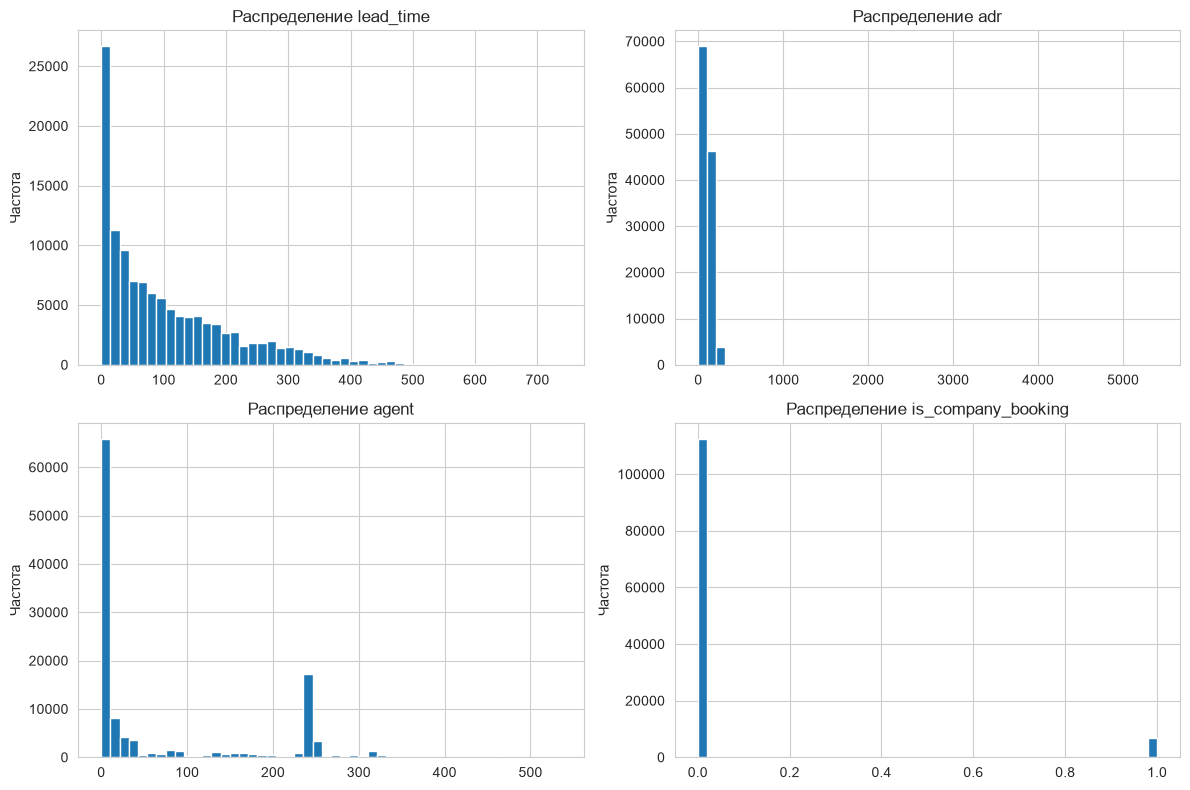

In [44]:
import matplotlib.pyplot as plt

cols_to_check = ['lead_time', 'adr', 'agent', 'is_company_booking']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for i, col in enumerate(cols_to_check):
    axes[i].hist(num_df[col].dropna(), bins=50)
    axes[i].set_title(f'Распределение {col}')
    axes[i].set_ylabel('Частота')

plt.tight_layout()
plt.show()


Логарифмируем (обработка выбросов)

In [45]:
import numpy as np

num_df['lead_time'] = np.log(num_df['lead_time'] + 1)
num_df['arrival_date_week_number'] = np.log(num_df['arrival_date_week_number'] + 1)
num_df['arrival_date_day_of_month'] = np.log(num_df['arrival_date_day_of_month'] + 1)
num_df['agent'] = np.log(num_df['agent'] + 1)
num_df['adr'] = np.log(num_df['adr'] + 1)

C:\ProjectsPython\ArtificialNeuralNetworksAndDeepLearning\.venv\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [46]:
num_df.var()

lead_time                         2.582757
arrival_date_week_number          0.440884
arrival_date_day_of_month         0.506325
stays_in_weekend_nights           0.990258
stays_in_week_nights              3.599010
adults                            0.330838
children                          0.159070
babies                            0.009508
is_repeated_guest                 0.030507
previous_cancellations            0.713887
previous_bookings_not_canceled    2.244415
agent                             3.535793
adr                               0.515480
required_car_parking_spaces       0.060201
total_of_special_requests         0.628652
is_company_booking                0.053551
dtype: float64

Смотрим, что получилось

In [47]:
X = pd.concat([cat_df, num_df], axis=1)

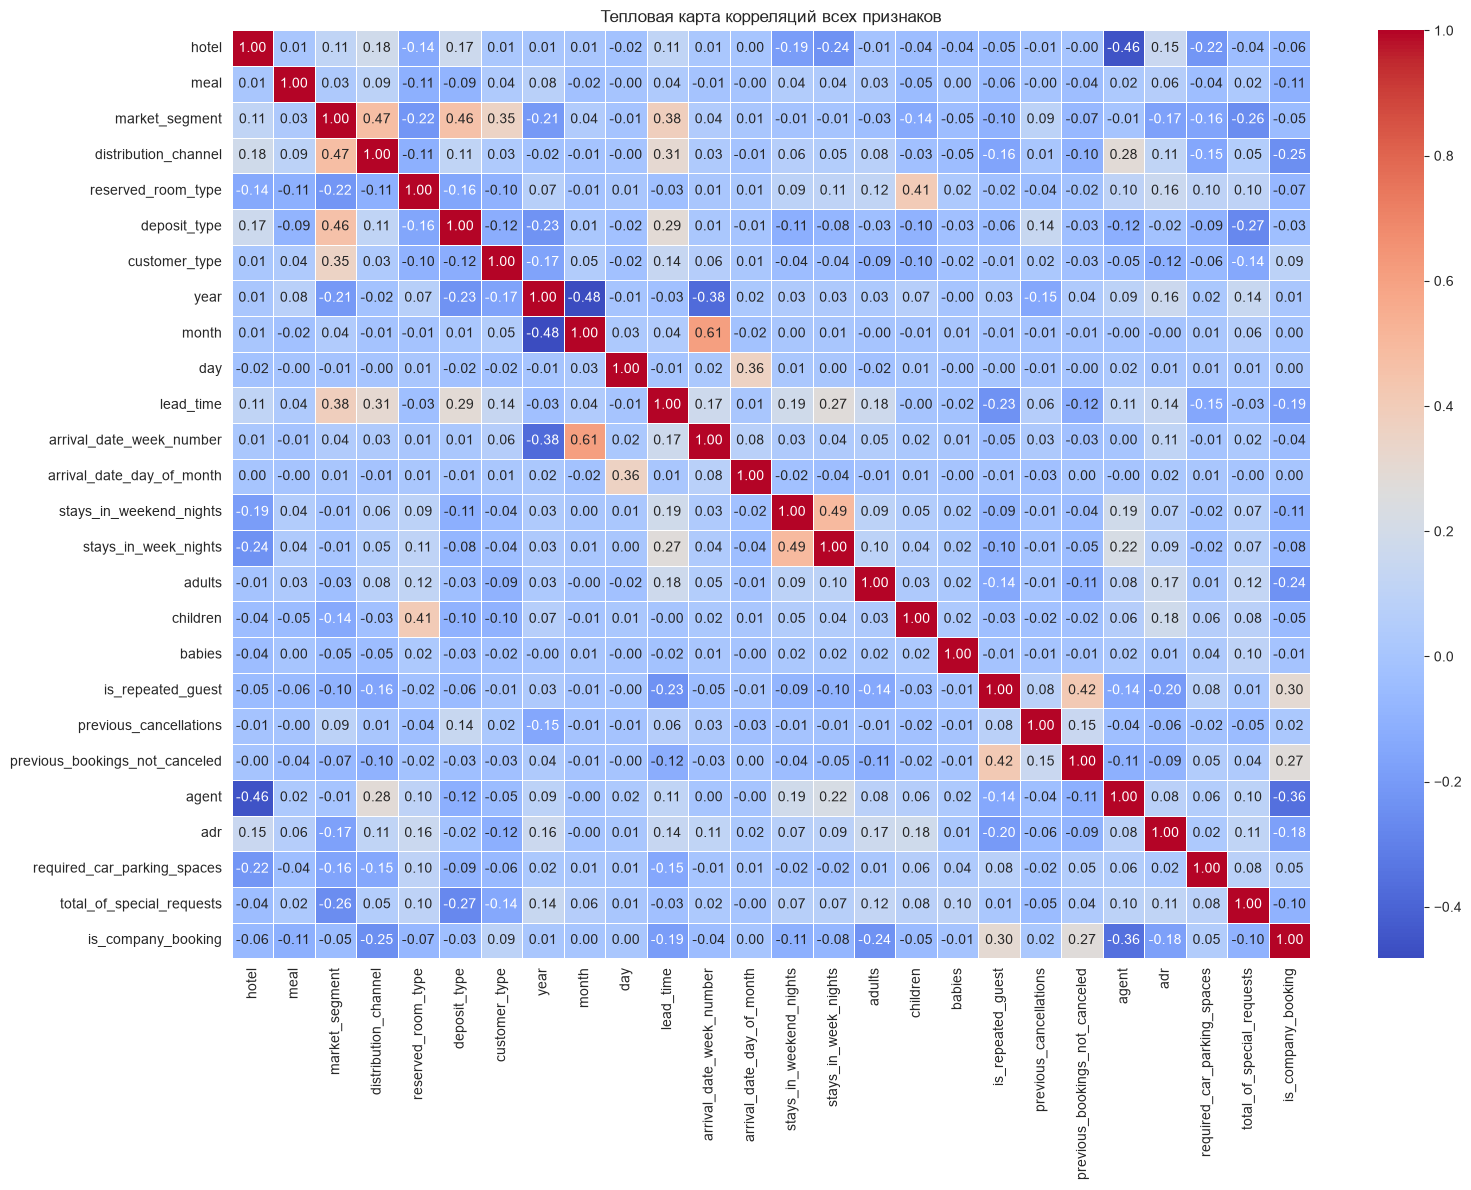

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = X.select_dtypes(include=['int32', 'int64', 'float64']).copy()

plt.figure(figsize=(16, 12))
corr_matrix = numeric_df.corr()  # можно добавить method='spearman'

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Тепловая карта корреляций всех признаков')
plt.tight_layout()
plt.show()

## 3. Разделение данных на выборки

In [49]:
Xcl = pd.concat([cat_df, num_df], axis=1)
ycl = df['is_canceled']

Xcl.shape, ycl.shape

((119210, 26), (119210,))

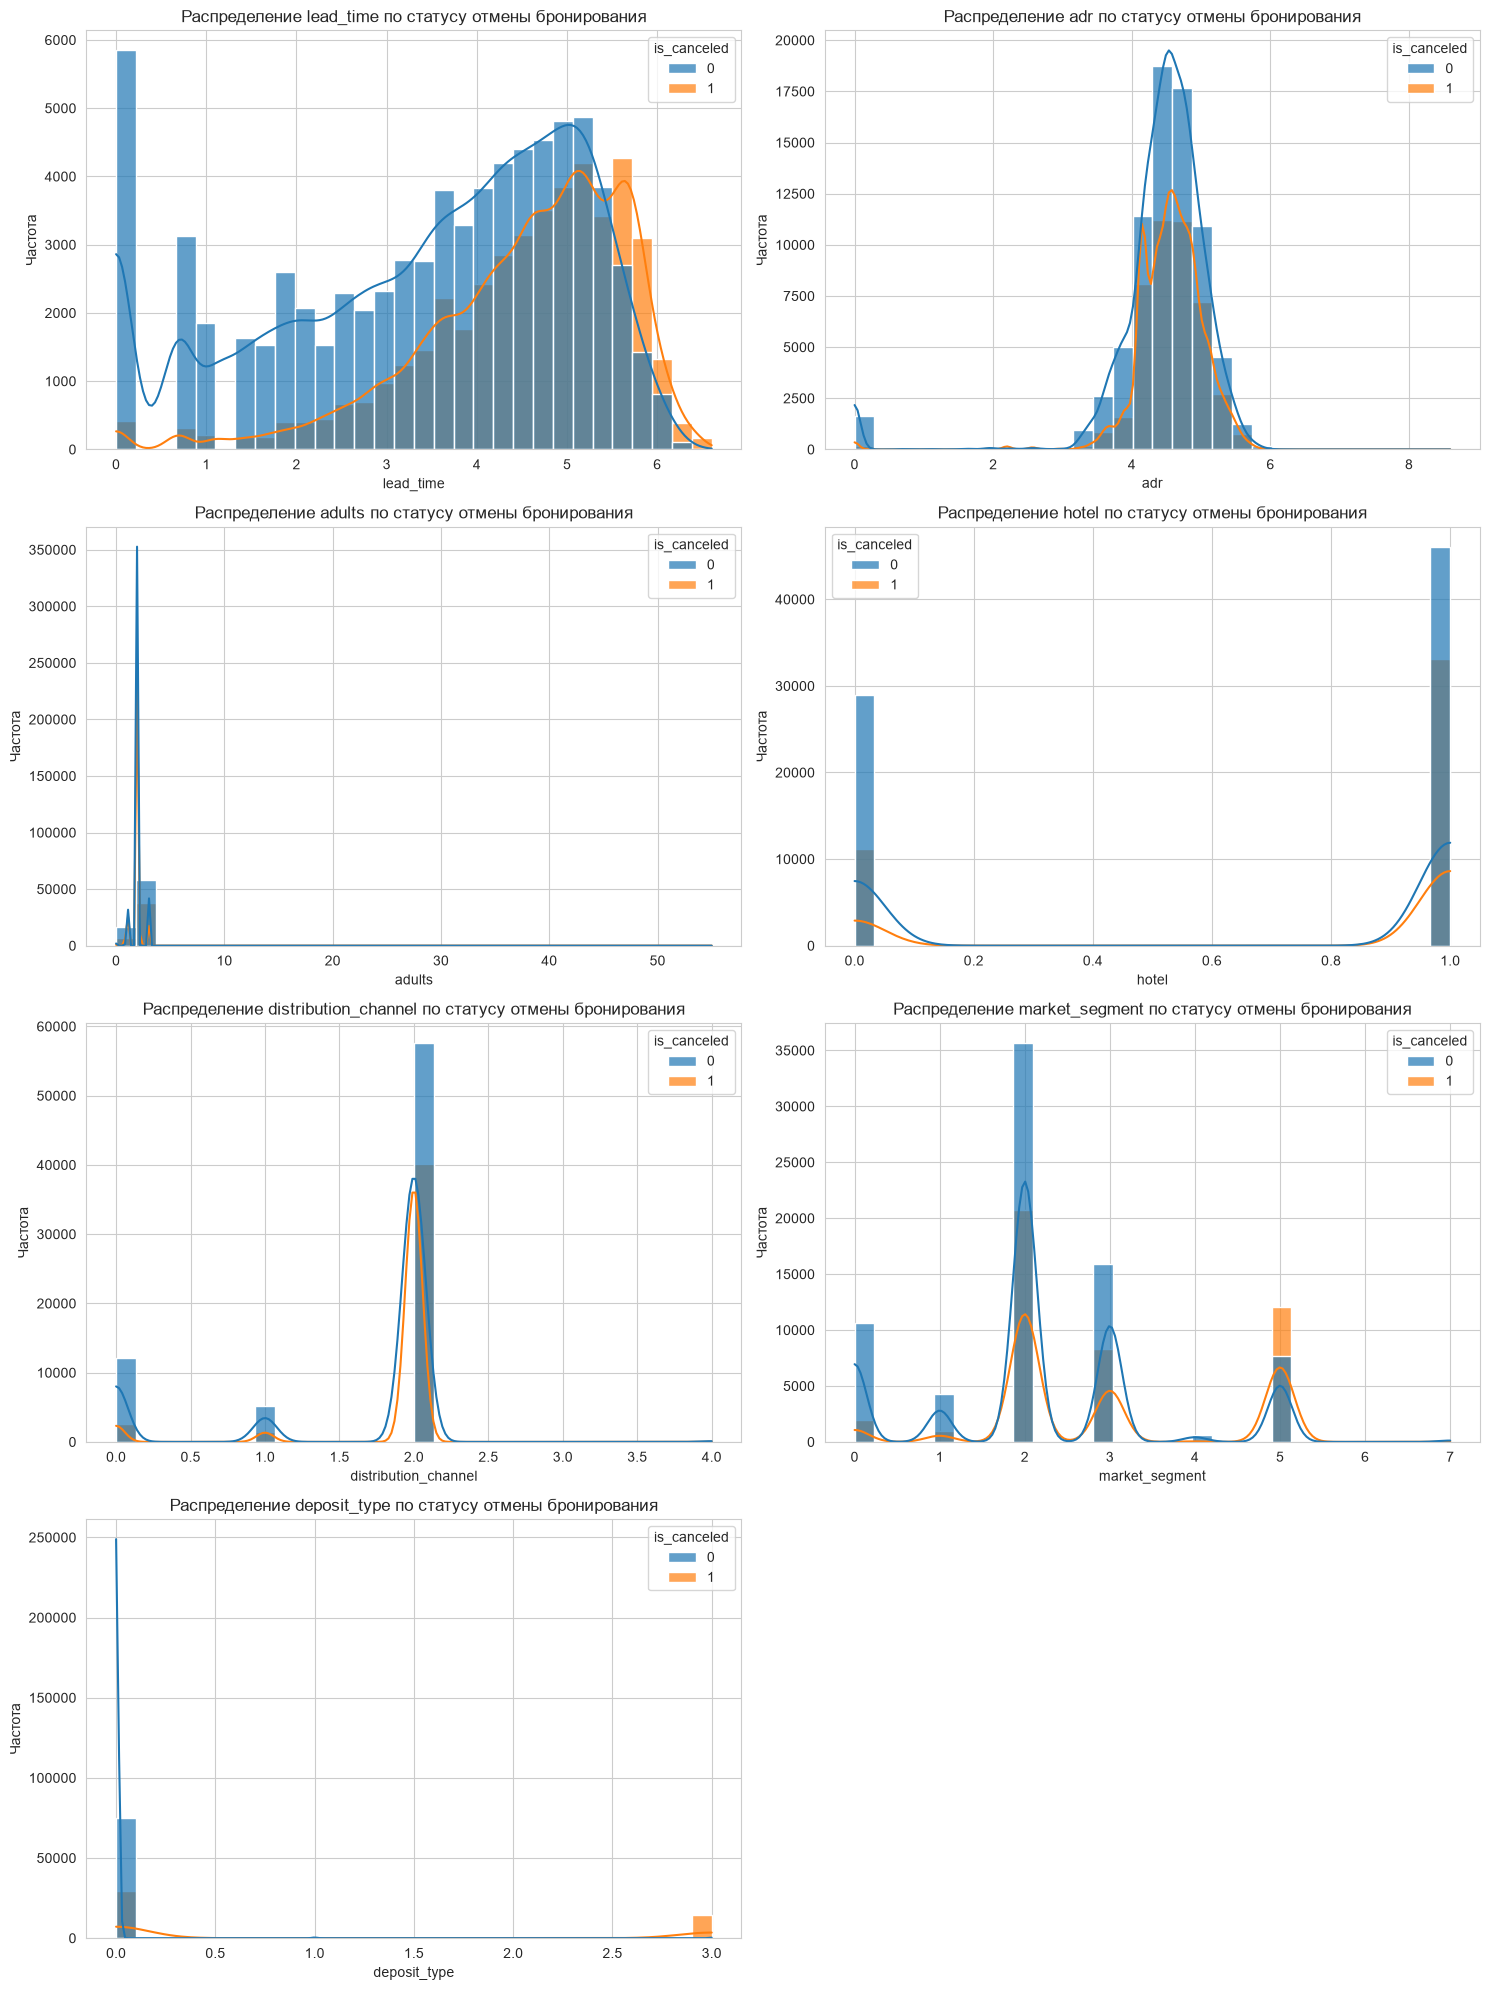

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# Выбираем признаки для визуализации (можете заменить на список интересующих столбцов из X)
features_to_plot = ['lead_time', 'adr', 'adults', 'hotel', 'distribution_channel', 'market_segment', 'deposit_type']

# Ограничиваем количество признаков на графике (если их слишком много)
features_to_plot = features_to_plot[:8]  # берём первые 8 признаков для примера

# Создаём фигуру с подзаграфами (4 строки, 2 столбца)
plt.figure(figsize=(15, 20))

# Объединяем X и y для удобства визуализации
data_with_target = pd.concat([Xcl[features_to_plot], ycl], axis=1)
data_with_target.columns = list(features_to_plot) + ['is_canceled']

# Рисуем графики
for i, feature in enumerate(features_to_plot, 1):
    plt.subplot(4, 2, i)
    sns.histplot(
        data=data_with_target,
        x=feature,
        hue='is_canceled',  # разбивка по целевому признаку (0 и 1)
        kde=True,           # добавляем оценку плотности (кривую KDE)
        bins=30,           # количество бинов
        alpha=0.7          # прозрачность
    )
    plt.title(f'Распределение {feature} по статусу отмены бронирования')
    plt.xlabel(feature)
    plt.ylabel('Частота')

# Настраиваем расположение графиков
plt.tight_layout()
plt.show()


In [51]:
print(np.isnan(X).any())  # есть ли хоть один NaN?
print(np.isnan(X).sum())  # сколько всего NaN
print(np.isnan(X).any(axis=0))  # в каких столбцах есть NaN

hotel                             False
meal                              False
market_segment                    False
distribution_channel              False
reserved_room_type                False
deposit_type                      False
customer_type                     False
year                              False
month                             False
day                               False
lead_time                         False
arrival_date_week_number          False
arrival_date_day_of_month         False
stays_in_weekend_nights           False
stays_in_week_nights              False
adults                            False
children                          False
babies                            False
is_repeated_guest                 False
previous_cancellations            False
previous_bookings_not_canceled    False
agent                             False
adr                                True
required_car_parking_spaces       False
total_of_special_requests         False


In [52]:
from sklearn.impute import SimpleImputer
import pandas as pd

imputer = SimpleImputer(strategy='median')
Xcl = pd.DataFrame(imputer.fit_transform(Xcl), columns=Xcl.columns)

In [53]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(Xcl)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [54]:
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

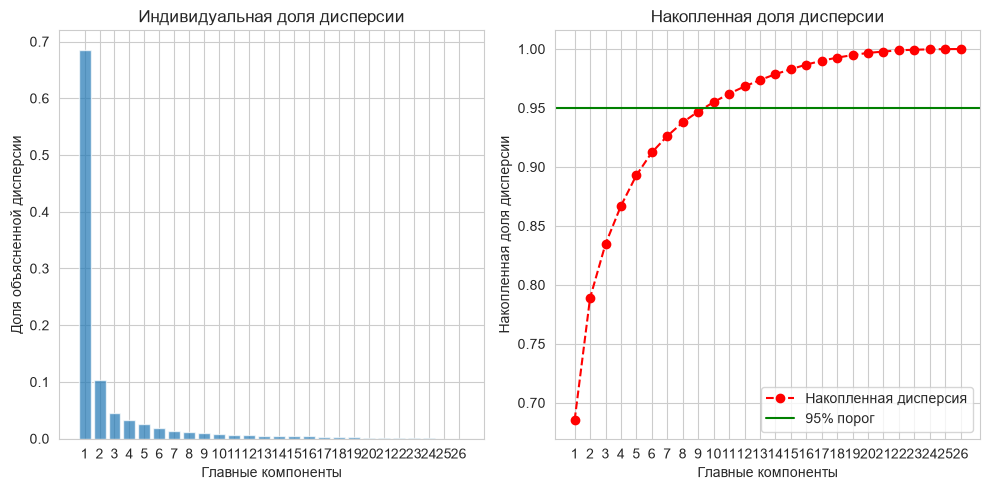

In [55]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.7, label='Индивидуальная дисперсия')
plt.xlabel('Главные компоненты')
plt.ylabel('Доля объясненной дисперсии')
plt.title('Индивидуальная доля дисперсии')
plt.xticks(range(1, len(explained_variance) + 1, 1))

plt.subplot(1, 2, 2)
plt.xticks(range(1, len(explained_variance) + 1, 1))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--', color='r',
         label='Накопленная дисперсия')
plt.xlabel('Главные компоненты')
plt.ylabel('Накопленная доля дисперсии')
plt.title('Накопленная доля дисперсии')
plt.axhline(y=0.95, color='g', linestyle='-', label='95% порог')
plt.legend()
plt.tight_layout()
plt.show()

In [56]:
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print(f"Для 90% дисперсии нужно: {n_components_90} компонент")
print(f"Для 95% дисперсии нужно: {n_components_95} компонент")

Для 90% дисперсии нужно: 6 компонент
Для 95% дисперсии нужно: 10 компонент


In [57]:
from sklearn.model_selection import train_test_split

# Разделение на Train / Validation / Test

# тестовая
Xcl_train_full, Xcl_test, ycl_train_full, ycl_test = train_test_split(
    Xcl, ycl, test_size=0.20, random_state=42
)

# валидационная
Xcl_train, Xcl_val, ycl_train, ycl_val = train_test_split(
    Xcl_train_full, ycl_train_full, test_size=0.20, random_state=42
)

print(f"Train shape:      {Xcl_train.shape}")
print(f"Validation shape: {Xcl_val.shape}")
print(f"Test shape:       {Xcl_test.shape}")

Train shape:      (76294, 26)
Validation shape: (19074, 26)
Test shape:       (23842, 26)


In [58]:
print(ycl.value_counts())

print(ycl.value_counts(normalize=True) * 100)

is_canceled
0    75011
1    44199
Name: count, dtype: int64
is_canceled
0    62.923412
1    37.076588
Name: proportion, dtype: float64


Балансировка

In [59]:
from imblearn.over_sampling import SMOTE
from collections import Counter

print(f"До балансировки: {Counter(ycl_train)}")

# Создаем объект SMOTE
smote = SMOTE(random_state=42)

# Генерируем новые данные (только для TRAIN!)
X_resampled, y_resampled = smote.fit_resample(Xcl_train, ycl_train)

print(f"После балансировки: {Counter(y_resampled)}")

До балансировки: Counter({0: 48037, 1: 28257})
После балансировки: Counter({0: 48037, 1: 48037})


## 4. Построить базовую нейронную сеть

In [60]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

mlp_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=10)),
    ('classifier', MLPClassifier(random_state=42, max_iter=300))
])

In [61]:
param_grid_mlp = {
    'classifier__hidden_layer_sizes': [(32,), (64,), (32, 16)], # Количество скрытых слоев и нейронов
    'classifier__activation': ['relu', 'tanh'],                  # Функция активации
    'classifier__learning_rate_init': [0.001, 0.01],             # Learning rate
    'classifier__batch_size': [32, 64],                          # Batch size
    'classifier__solver': ['adam', 'sgd']                        # Оптимизатор
}

In [62]:
# from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
# import numpy as np
# import time
#
# print("Начинаем перебор параметров для Neural Network (MLP)...\n")
# print(f"{'layers':>10} | {'activation':>10} | {'lr':>8} | {'batch':>6} | {'solver':>8} | {'Acc':>8} | {'F1':>8} | Time")
# print("-" * 95)
#
# best_f1_mlp = -np.inf
# best_params_mlp = None
# start_total = time.time()
#
# # Перебираем комбинации вручную в стиле вашего примера
# for layers in param_grid_mlp['classifier__hidden_layer_sizes']:
#     for activation in param_grid_mlp['classifier__activation']:
#         for lr in param_grid_mlp['classifier__learning_rate_init']:
#             for batch in param_grid_mlp['classifier__batch_size']:
#                 for solver in param_grid_mlp['classifier__solver']:
#
#                     start = time.time()
#
#                     mlp_pipeline.set_params(
#                         classifier__hidden_layer_sizes=layers,
#                         classifier__activation=activation,
#                         classifier__learning_rate_init=lr,
#                         classifier__batch_size=batch,
#                         classifier__solver=solver
#                     )
#
#                     # Обучаем НА СБАЛАНСИРОВАННЫХ ДАННЫХ (после SMOTE)
#                     mlp_pipeline.fit(X_resampled, y_resampled)
#                     ycl_pred_val = mlp_pipeline.predict(Xcl_val)
#
#                     acc = accuracy_score(ycl_val, ycl_pred_val)
#                     f1 = f1_score(ycl_val, ycl_pred_val)
#                     prec = precision_score(ycl_val, ycl_pred_val, zero_division=0)
#                     rec = recall_score(ycl_val, ycl_pred_val, zero_division=0)
#
#                     elapsed = time.time() - start
#
#                     layers_str = str(layers)
#                     print(f"{layers_str:>10} | {activation:>10} | {lr:8} | {batch:6} | {solver:>8} | {acc:8.3f} | {f1:8.3f} | {elapsed:.1f}s")
#
#                     if f1 > best_f1_mlp:
#                         best_f1_mlp = f1
#                         best_params_mlp = (layers, activation, lr, batch, solver)
#                         best_acc_mlp = acc
#                         best_prec_mlp = prec
#                         best_rec_mlp = rec
#
# print("\n" + "="*95)
# print(f"Лучшая комбинация параметров для Neural Network:")
# print(f"hidden_layer_sizes={best_params_mlp[0]}, activation={best_params_mlp[1]}, learning_rate_init={best_params_mlp[2]}, batch_size={best_params_mlp[3]}, solver={best_params_mlp[4]}")
# print(f"Accuracy = {best_acc_mlp:.4f} | Precision = {best_prec_mlp:.4f} | Recall = {best_rec_mlp:.4f} | F1-Score = {best_f1_mlp:.4f}")
# print(f"Общее время: {(time.time() - start_total):.1f} секунд")

In [63]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=mlp_pipeline,
    param_grid=param_grid_mlp,
    scoring='f1',       # Оптимизируем по F1-мере
    cv=3,               # Кросс-валидация
    n_jobs=-1,
    verbose=2           # Вывод прогресса в консоль
)

print("Запуск параллельного поиска параметров...")
grid_search.fit(X_resampled, y_resampled)

print("\nЛучшие параметры:")
print(grid_search.best_params_)
print(f"Лучший F1 на кросс-валидации: {grid_search.best_score_:.4f}")

Запуск параллельного поиска параметров...
Fitting 3 folds for each of 48 candidates, totalling 144 fits

Лучшие параметры:
{'classifier__activation': 'tanh', 'classifier__batch_size': 64, 'classifier__hidden_layer_sizes': (32, 16), 'classifier__learning_rate_init': 0.01, 'classifier__solver': 'sgd'}
Лучший F1 на кросс-валидации: 0.8114


In [64]:
import pandas as pd

results_df = pd.DataFrame(grid_search.cv_results_)

columns_to_show = [
    'param_classifier__hidden_layer_sizes',
    'param_classifier__activation',
    'param_classifier__learning_rate_init',
    'param_classifier__batch_size',
    'param_classifier__solver',
    'mean_test_score',
    'rank_test_score',
    'mean_fit_time'
]

results_df = results_df[columns_to_show]

results_df.columns = ['Layers', 'Activation', 'LR', 'Batch', 'Solver', 'F1_Score', 'Rank', 'Time_sec']

results_df = results_df.sort_values(by='F1_Score', ascending=False).reset_index(drop=True)

pd.set_option('display.max_rows', 50)
print("Таблица всех проверенных комбинаций:")
results_df

Таблица всех проверенных комбинаций:


,Layers,Activation,LR,Batch,Solver,F1_Score,Rank,Time_sec
0,"(32, 16)",tanh,0.010,64,sgd,0.811363,1,52.691073
1,"(32, 16)",tanh,0.001,32,adam,0.811225,2,222.230338
2,"(32, 16)",tanh,0.010,32,sgd,0.809828,3,140.213136
3,"(32, 16)",tanh,0.001,32,sgd,0.809618,4,217.674277
4,"(32, 16)",tanh,0.001,64,adam,0.808811,5,102.949639
5,"(32, 16)",relu,0.010,64,sgd,0.808165,6,44.891805
6,"(32, 16)",relu,0.001,32,adam,0.807329,7,146.919711
7,"(64,)",tanh,0.010,32,sgd,0.807057,8,130.817711
8,"(32, 16)",relu,0.001,64,adam,0.805734,9,88.165395
9,"(32, 16)",relu,0.001,32,sgd,0.805534,10,140.976300


## 5. Исследовать влияние архитектуры сети на качество

**Количество скрытых слоев и нейронов:** Эксперименты показали, что более глубокая архитектура с двумя скрытыми слоями (32, 16) стабильно превосходит однослойные сети (как с меньшим, так и с большим числом нейронов — (32,) и (64,)). Конфигурация (32, 16) занимает весь верх таблицы, что говорит о важности последовательного уменьшения размерности признаков на скрытых уровнях для данной задачи.

**Функции активации:** Абсолютным лидером среди функций активации стала tanh (гиперболический тангенс) — именно она присутствует во всех лучших моделях верхней части таблицы. Функция relu в данном случае уступает по качеству и начинает массово встречаться только ближе к середине и концу списка.

## 6. Исследовать влияние как минимум двух параметров обучения:

**Скорость обучения (Learning Rate):** Шаг обучения 0.01 продемонстрировал более высокую эффективность и скорость сходимости в сочетании с оптимизатором SGD. Мелкий шаг 0.01 (в частности, сопряженный с 0.001 у других конфигураций) часто приводил к значительному росту времени обучения (до 100–220 секунд на кросс-валидацию) без существенного прироста качества.

**Оптимизатор и размер батча:** Лучший результат по метрике F1 (0.8114) показала комбинация оптимизатора sgd с размером мини-батча 64. При этом оптимизатор adam также демонстрирует конкурентные результаты и держится в топе, однако требует больше времени на выполнение итераций по сравнению с sgd.

## 7. Исследовать проблему переобучения с использованием Dropout, weight decay или early stopping.

In [65]:
X_train_small = X_resampled[:10000]
y_train_small = y_resampled[:10000]

In [72]:
mlp_not_regularized = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='tanh',
    learning_rate_init=0.01,
    batch_size=64,
    solver='sgd',

    random_state=42,
    max_iter=300
)

In [68]:
mlp_regularized = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='tanh',
    learning_rate_init=0.01,
    batch_size=64,
    solver='sgd',

    early_stopping=True,
    validation_fraction=0.1, # Доля данных для ранней остановки (10%)
    n_iter_no_change=10,     # Сколько эпох ждать без улучшений перед остановкой
    alpha=0.001,             # Weight Decay (L2-штраф за большие веса)

    random_state=42,
    max_iter=300
)

In [73]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import time

start = time.time()

# mlp_regularized.fit(X_train_small, y_train_small)
mlp_not_regularized.fit(X_resampled, y_resampled)

ycl_pred_val = mlp_not_regularized.predict(Xcl_val)

elapsed = time.time() - start

acc = accuracy_score(ycl_val, ycl_pred_val)
f1 = f1_score(ycl_val, ycl_pred_val)
prec = precision_score(ycl_val, ycl_pred_val, zero_division=0)
rec = recall_score(ycl_val, ycl_pred_val, zero_division=0)

print(f"\nГотово за {elapsed:.1f} сек.!")
print(f"Фактическое количество пройденных эпох: {mlp_not_regularized.n_iter_}")
print(f"Accuracy  = {acc:.4f}")
print(f"Precision = {prec:.4f}")
print(f"Recall    = {rec:.4f}")
print(f"F1-Score  = {f1:.4f}")


Готово за 26.4 сек.!
Фактическое количество пройденных эпох: 98
Accuracy  = 0.9462
Precision = 0.9299
Recall    = 0.9242
F1-Score  = 0.9270


In [71]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import time

start = time.time()

# mlp_regularized.fit(X_train_small, y_train_small)
mlp_regularized.fit(X_resampled, y_resampled)

ycl_pred_val = mlp_regularized.predict(Xcl_val)

elapsed = time.time() - start

acc = accuracy_score(ycl_val, ycl_pred_val)
f1 = f1_score(ycl_val, ycl_pred_val)
prec = precision_score(ycl_val, ycl_pred_val, zero_division=0)
rec = recall_score(ycl_val, ycl_pred_val, zero_division=0)

print(f"\nГотово за {elapsed:.1f} сек.!")
print(f"Фактическое количество пройденных эпох: {mlp_regularized.n_iter_}")
print(f"Accuracy  = {acc:.4f}")
print(f"Precision = {prec:.4f}")
print(f"Recall    = {rec:.4f}")
print(f"F1-Score  = {f1:.4f}")


Готово за 5.6 сек.!
Фактическое количество пройденных эпох: 23
Accuracy  = 0.9166
Precision = 0.8923
Recall    = 0.8811
F1-Score  = 0.8867


Вывод, стало быстрее

Смотрим, что получилось на тестовой выборке

In [74]:
from sklearn.metrics import classification_report, accuracy_score, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt


mlp_final = mlp_not_regularized # лучшая модель

# проверяем на тестовыой выборке
ycl_pred_test_mlp = mlp_final.predict(Xcl_test)

print(f"Neural Network (MLP) — Результаты на ТЕСТОВОЙ выборке:")
print(f"Accuracy  = {accuracy_score(ycl_test, ycl_pred_test_mlp):.4f}")
print(f"Precision = {precision_score(ycl_test, ycl_pred_test_mlp, zero_division=0):.4f}")
print(f"Recall    = {recall_score(ycl_test, ycl_pred_test_mlp, zero_division=0):.4f}")
print(f"F1-Score  = {f1_score(ycl_test, ycl_pred_test_mlp, zero_division=0):.4f}")

print("\nДетальный отчет (Classification Report):")
print(classification_report(ycl_test, ycl_pred_test_mlp))

Neural Network (MLP) — Результаты на ТЕСТОВОЙ выборке:
Accuracy  = 0.9498
Precision = 0.9397
Recall    = 0.9247
F1-Score  = 0.9321

Детальный отчет (Classification Report):
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     14958
           1       0.94      0.92      0.93      8884

    accuracy                           0.95     23842
   macro avg       0.95      0.94      0.95     23842
weighted avg       0.95      0.95      0.95     23842



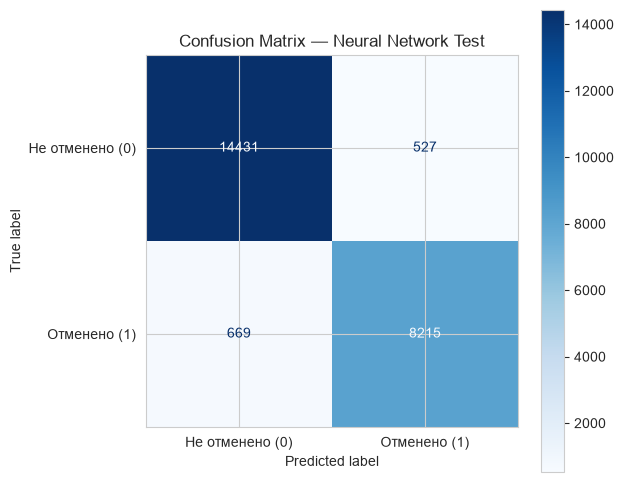

In [75]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


fig, ax = plt.subplots(figsize=(6, 6))
cm = confusion_matrix(ycl_test, ycl_pred_test_mlp)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Не отменено (0)', 'Отменено (1)'])
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title("Confusion Matrix — Neural Network Test")
plt.show()

## 8. Сравнить нейронную сеть с простым классическим алгоритмом для той же задачи.

логистическая регрессия

In [79]:
from sklearn.linear_model import SGDClassifier

log_reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=10)),
    ('classifier', SGDClassifier(loss='log_loss', random_state=42, max_iter=1000, early_stopping=True, validation_fraction=0.1, tol=1e-3))
])

In [80]:
param_grid_log = {
    'classifier__alpha': [0.0001, 0.001, 0.01],
    'classifier__learning_rate': ['optimal', 'adaptive'],
    'classifier__penalty': ['l2', 'l1', 'elasticnet'],
    'classifier__eta0': [0.01, 0.1]
}

In [81]:
grid_search_log = GridSearchCV(
    estimator=log_reg_pipeline,
    param_grid=param_grid_log,
    scoring='f1',
    cv=3,
    n_jobs=-1,
    verbose=1
)

print("Запуск быстрого параллельного поиска для Logistic Regression (SGD)...")
grid_search_log.fit(X_resampled, y_resampled)

print("\n" + "="*50)
print("Лучшие параметры для Logistic Regression:")
print(grid_search_log.best_params_)
print(f"Лучший F1 на кросс-валидации: {grid_search_log.best_score_:.4f}")

best_params_log = (
    grid_search_log.best_params_['classifier__alpha'],
    grid_search_log.best_params_['classifier__learning_rate'],
    grid_search_log.best_params_['classifier__penalty'],
    grid_search_log.best_params_['classifier__eta0']
)

Запуск быстрого параллельного поиска для Logistic Regression (SGD)...
Fitting 3 folds for each of 36 candidates, totalling 108 fits

Лучшие параметры для Logistic Regression:
{'classifier__alpha': 0.001, 'classifier__eta0': 0.01, 'classifier__learning_rate': 'optimal', 'classifier__penalty': 'l1'}
Лучший F1 на кросс-валидации: 0.6987


In [82]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report

log_reg_pipeline.set_params(
    classifier__alpha=grid_search_log.best_params_['classifier__alpha'],
    classifier__learning_rate=grid_search_log.best_params_['classifier__learning_rate'],
    classifier__penalty=grid_search_log.best_params_['classifier__penalty'],
    classifier__eta0=grid_search_log.best_params_['classifier__eta0']
)

log_reg_pipeline.fit(X_resampled, y_resampled)

ycl_pred_test_log = log_reg_pipeline.predict(Xcl_test)

print(f"Logistic Regression — Результаты на ТЕСТОВОЙ выборке:")
print(f"Accuracy  = {accuracy_score(ycl_test, ycl_pred_test_log):.4f}")
print(f"Precision = {precision_score(ycl_test, ycl_pred_test_log, zero_division=0):.4f}")
print(f"Recall    = {recall_score(ycl_test, ycl_pred_test_log, zero_division=0):.4f}")
print(f"F1-Score  = {f1_score(ycl_test, ycl_pred_test_log, zero_division=0):.4f}")
print("\nДетальный отчет (Classification Report):")
print(classification_report(ycl_test, ycl_pred_test_log))

Logistic Regression — Результаты на ТЕСТОВОЙ выборке:
Accuracy  = 0.7206
Precision = 0.6177
Recall    = 0.6565
F1-Score  = 0.6365

Детальный отчет (Classification Report):
              precision    recall  f1-score   support

           0       0.79      0.76      0.77     14958
           1       0.62      0.66      0.64      8884

    accuracy                           0.72     23842
   macro avg       0.70      0.71      0.70     23842
weighted avg       0.72      0.72      0.72     23842



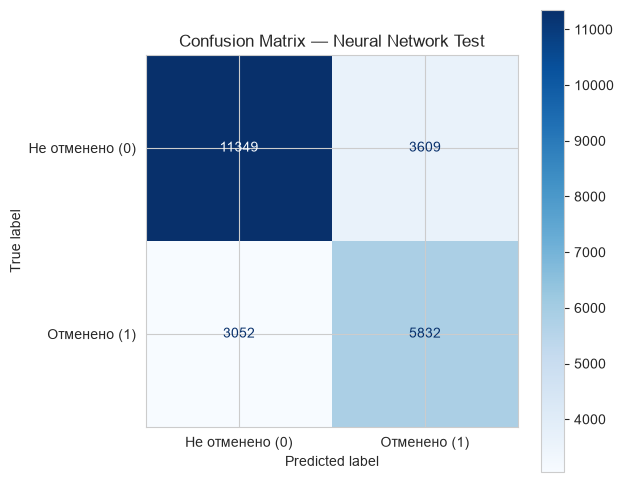

In [83]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


fig, ax = plt.subplots(figsize=(6, 6))
cm = confusion_matrix(ycl_test, ycl_pred_test_log)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Не отменено (0)', 'Отменено (1)'])
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title("Confusion Matrix — Neural Network Test")
plt.show()

итоговое сравнение

Сводная таблица результатов на тестовой выборке:


,Logistic Regression,Neural Network (MLP)
Metric,,
Accuracy,0.720619,0.949836
Precision,0.617731,0.939716
Recall,0.656461,0.924696
F1-Score,0.636508,0.932146


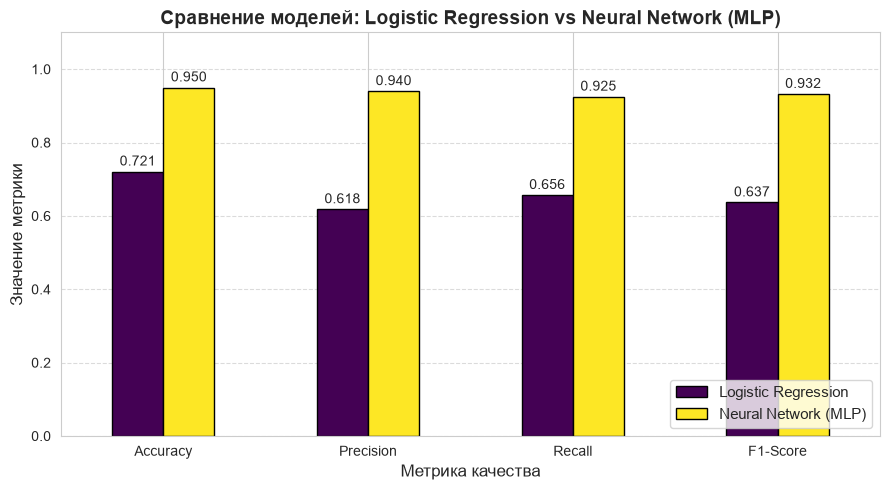

In [85]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

metrics_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Logistic Regression': [
        accuracy_score(ycl_test, ycl_pred_test_log),
        precision_score(ycl_test, ycl_pred_test_log, zero_division=0),
        recall_score(ycl_test, ycl_pred_test_log, zero_division=0),
        f1_score(ycl_test, ycl_pred_test_log, zero_division=0)
    ],
    'Neural Network (MLP)': [
        accuracy_score(ycl_test, ycl_pred_test_mlp),
        precision_score(ycl_test, ycl_pred_test_mlp, zero_division=0),
        recall_score(ycl_test, ycl_pred_test_mlp, zero_division=0),
        f1_score(ycl_test, ycl_pred_test_mlp, zero_division=0)
    ]
}

df_comparison = pd.DataFrame(metrics_data)
df_comparison.set_index('Metric', inplace=True)

print("Сводная таблица результатов на тестовой выборке:")
display(df_comparison)

ax = df_comparison.plot(kind='bar', figsize=(9, 5), rot=0, colormap='viridis', edgecolor='black')
plt.title('Сравнение моделей: Logistic Regression vs Neural Network (MLP)', fontsize=14, fontweight='bold')
plt.ylabel('Значение метрики', fontsize=12)
plt.xlabel('Метрика качества', fontsize=12)
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 7),
                textcoords='offset points',
                fontsize=10)

plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()